# Exercise 5 - Retinal Blood-Vessel Extraction

## Objective
Inspect the six color retinal images, including illumination, contrast, vessel width, and color channels. Implement classical Otsu thresholding, adaptive thresholding, and K-means vessel extraction. Compare green, red, and blue channels, test local-threshold and K-means parameters, and assess CLAHE contrast enhancement.

## Data and evaluation
Each image has a `manual1` vessel reference and a `training_mask` field-of-view mask. Predictions and all Dice, Precision, and Recall counts are restricted to the valid training-mask pixels. Results include per-image scores, the mean across images for each method, parameter/channel/preprocessing comparisons, and visual examples for three images.


In [1]:
from pathlib import Path
import csv
import html
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, HTML

cwd = Path.cwd()
ROOT = next(
    (p / "5 Region Extraction" for p in (cwd, *cwd.parents)
     if (p / "5 Region Extraction" / "Input").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Cannot find 5 Region Extraction/Input from the current directory.")

IMAGE_DIR = ROOT / "Input" / "Images"
MASK_DIR = ROOT / "Input" / "Masks"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_paths = sorted(IMAGE_DIR.glob("*.tif"))
if len(image_paths) != 6:
    raise ValueError(f"Expected six retinal images in {IMAGE_DIR}, found {len(image_paths)}.")

DATASET = {}
for image_path in image_paths:
    image_id = image_path.stem
    manual_path = MASK_DIR / f"{image_id}_manual1.gif"
    training_path = MASK_DIR / f"{image_id}_training_mask.gif"
    missing = [path for path in (manual_path, training_path) if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Missing masks for image {image_id}: {missing}")

    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    reference = cv2.imread(str(manual_path), cv2.IMREAD_GRAYSCALE)
    valid_mask = cv2.imread(str(training_path), cv2.IMREAD_GRAYSCALE)
    if image is None or reference is None or valid_mask is None:
        raise OSError(f"Could not decode image or masks for {image_id}.")
    if image.shape[:2] != reference.shape or reference.shape != valid_mask.shape:
        raise ValueError(f"Image/mask dimensions do not match for {image_id}.")
    if not np.any(valid_mask):
        raise ValueError(f"Training mask for image {image_id} contains no valid pixels.")

    DATASET[image_id] = {
        "image": image,
        "reference": reference > 0,
        "valid_mask": valid_mask > 0,
    }

print(f"Loaded {len(DATASET)} aligned image/reference/FOV triples from {ROOT}.")


Loaded 6 aligned image/reference/FOV triples from c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\5 Region Extraction.


## Preprocessing and methods
All methods operate on one 8-bit channel at a time. The channel comparison runs every method on blue, green, and red; the main comparison uses the green channel without enhancement so its method scores are directly comparable.

- **Otsu:** automatically selects a global dark-vessel threshold from valid field-of-view pixels.
- **Adaptive:** Gaussian local thresholding; the sweep tests block sizes 15/25/35 and C values 2/5/8.
- **K-means:** groups valid-pixel intensities and selects the darkest cluster as vessels; the sweep tests K=2/3/4.
- **CLAHE:** a separate raw-versus-enhanced comparison tests local contrast enhancement on the green channel.

The parameter and preprocessing experiments are reported separately from the fixed-configuration main comparison.


In [2]:
CHANNEL_INDEX = {"blue": 0, "green": 1, "red": 2}
METHODS = ("otsu", "adaptive", "kmeans")
CLAHE_CONFIG = {"clip_limit": 2.0, "tile_grid_size": (8, 8)}


def prepare_retina(image, channel="green", clahe_config=None):
    """Return an 8-bit single-channel image, optionally enhanced with CLAHE."""
    if image is None or image.ndim not in (2, 3):
        raise ValueError("image must be a non-empty grayscale or color image.")
    if image.ndim == 2:
        if channel not in ("gray", "grayscale", "green"):
            raise ValueError("A grayscale image only supports the gray channel.")
        prepared = image.copy()
    else:
        if image.shape[2] != 3:
            raise ValueError("Color images must have exactly three BGR channels.")
        channel = channel.lower()
        if channel in CHANNEL_INDEX:
            prepared = image[:, :, CHANNEL_INDEX[channel]].copy()
        elif channel in ("gray", "grayscale"):
            prepared = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        else:
            raise ValueError(f"Unsupported channel: {channel!r}.")

    if prepared.dtype != np.uint8:
        raise ValueError("Input channels must use uint8 intensity values.")
    if clahe_config is not None:
        clip_limit = float(clahe_config.get("clip_limit", 2.0))
        tile_grid_size = tuple(clahe_config.get("tile_grid_size", (8, 8)))
        if clip_limit <= 0 or len(tile_grid_size) != 2 or min(tile_grid_size) < 1:
            raise ValueError("CLAHE needs a positive clip limit and two positive tile dimensions.")
        clahe = cv2.createCLAHE(
            clipLimit=clip_limit,
            tileGridSize=(int(tile_grid_size[0]), int(tile_grid_size[1])),
        )
        prepared = clahe.apply(prepared)
    return np.ascontiguousarray(prepared)


def extract_vessels(prepared, method, config=None):
    """Extract dark vessel pixels; an optional valid_mask limits fitting and output."""
    config = dict(config or {})
    gray = np.asarray(prepared)
    if gray.ndim != 2 or gray.dtype != np.uint8 or gray.size == 0:
        raise ValueError("prepared must be a non-empty 8-bit grayscale image.")

    valid_mask = np.asarray(config.pop("valid_mask", np.ones(gray.shape, dtype=bool)), dtype=bool)
    if valid_mask.shape != gray.shape:
        raise ValueError("valid_mask and prepared image must have identical dimensions.")
    if not valid_mask.any():
        raise ValueError("valid_mask contains no pixels.")

    method = method.lower()
    if method == "otsu":
        samples = np.ascontiguousarray(gray[valid_mask].reshape(-1, 1))
        threshold, _ = cv2.threshold(samples, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
        prediction = gray <= threshold
    elif method == "adaptive":
        block_size = int(config.get("block_size", 25))
        constant = float(config.get("C", 5))
        if block_size < 3 or block_size % 2 == 0 or block_size > min(gray.shape):
            raise ValueError("Adaptive block_size must be odd, at least 3, and no larger than the image.")
        prediction = cv2.adaptiveThreshold(
            gray,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV,
            block_size,
            constant,
        ) > 0
    elif method == "kmeans":
        k = int(config.get("k", 3))
        if k < 2 or k > 10:
            raise ValueError("K-means k must be between 2 and 10.")
        values = gray[valid_mask]
        if np.unique(values).size < k:
            raise ValueError("K-means requires at least k distinct valid-pixel intensities.")
        samples = np.ascontiguousarray(values.reshape(-1, 1), dtype=np.float32)
        cv2.setRNGSeed(int(config.get("random_seed", 0)))
        criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.2)
        _, labels, centers = cv2.kmeans(
            samples, k, None, criteria, 1, cv2.KMEANS_PP_CENTERS
        )
        darkest_cluster = int(np.argmin(centers[:, 0]))
        prediction = np.zeros(gray.shape, dtype=bool)
        prediction[valid_mask] = labels.ravel() == darkest_cluster
    else:
        raise ValueError(f"Unsupported extraction method: {method!r}.")

    return np.asarray(prediction, dtype=bool) & valid_mask


def binary_metrics(prediction, reference, valid_mask):
    """Compute Dice, Precision, and Recall using only valid field-of-view pixels."""
    prediction = np.asarray(prediction, dtype=bool)
    reference = np.asarray(reference, dtype=bool)
    valid_mask = np.asarray(valid_mask, dtype=bool)
    if prediction.shape != reference.shape or reference.shape != valid_mask.shape:
        raise ValueError("prediction, reference, and valid_mask must have identical dimensions.")
    if not valid_mask.any():
        raise ValueError("valid_mask contains no pixels.")

    predicted = prediction[valid_mask]
    actual = reference[valid_mask]
    tp = int(np.count_nonzero(predicted & actual))
    fp = int(np.count_nonzero(predicted & ~actual))
    fn = int(np.count_nonzero(~predicted & actual))
    precision = tp / (tp + fp) if tp + fp else float(not actual.any())
    recall = tp / (tp + fn) if tp + fn else 1.0
    dice = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0
    return {"Dice": dice, "Precision": precision, "Recall": recall, "TP": tp, "FP": fp, "FN": fn}


def estimate_median_vessel_width(reference):
    """Estimate vessel diameter from the reference skeleton and its distance transform."""
    binary = np.asarray(reference, dtype=bool)
    if binary.ndim != 2:
        raise ValueError("reference must be a 2-D binary mask.")
    if not binary.any():
        return float("nan")
    foreground = binary.astype(np.uint8) * 255
    distance = cv2.distanceTransform(foreground, cv2.DIST_L2, 5)
    work = foreground.copy()
    skeleton = np.zeros_like(work)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    while cv2.countNonZero(work):
        eroded = cv2.erode(work, kernel)
        opened = cv2.dilate(eroded, kernel)
        skeleton = cv2.bitwise_or(skeleton, cv2.subtract(work, opened))
        work = eroded
    diameters = 2 * distance[skeleton > 0]
    return float(np.median(diameters)) if diameters.size else float("nan")


PREPARED = {}
for image_id, item in DATASET.items():
    for channel in ("blue", "green", "red"):
        PREPARED[(image_id, channel, "raw")] = prepare_retina(item["image"], channel)
    PREPARED[(image_id, "green", "clahe")] = prepare_retina(
        item["image"], "green", CLAHE_CONFIG
    )

print("Methods and preprocessing functions are ready.")


Methods and preprocessing functions are ready.


## Evaluation and reporting
The main table uses fixed, common settings (green channel, no CLAHE) so the three methods are comparable. All scores are computed per image inside `training_mask`, then averaged across the six images as requested. Separate tables quantify channel choice, adaptive block/C values, K-means K, and raw-versus-CLAHE effects.

The notebook saves CSV tables and two figures in `outputs/`: channel inspection for all six images, plus reference/prediction comparisons for images 01, 03, and 06. The parameter sweep is an exploratory comparison on the supplied references, not a held-out test set.


image_id,height,width,valid_fov_fraction,reference_vessel_fraction,median_reference_vessel_width_px,blue_mean,blue_std,blue_p95_minus_p5,green_mean,green_std,green_p95_minus_p5,red_mean,red_std,red_p95_minus_p5
01,584,565,0.6894,0.1246,2.8000,50.6034,8.7795,23.0000,91.1602,14.9594,38.0000,170.8193,27.1138,77.0000
02,584,565,0.6856,0.1259,2.8000,82.6502,10.8079,22.0000,124.7166,17.7143,38.0000,169.7643,25.5587,75.0000
03,584,565,0.6901,0.0874,2.8000,62.0361,14.9460,41.0000,107.9755,29.9723,80.0000,208.5218,41.2043,112.0000
04,584,565,0.6822,0.1222,2.8000,34.2536,5.0472,14.0000,62.8255,10.3086,26.0000,131.8787,22.3184,66.0000
05,584,565,0.6879,0.1101,2.8000,39.2471,7.0011,17.0000,72.4656,13.9183,36.0000,129.6255,25.5748,73.0000
06,584,565,0.6916,0.0952,4.0000,61.8698,14.9281,45.0000,118.0005,28.3379,88.0000,246.2233,26.7207,56.0000


image_id,method,channel,preprocessing,Dice,Precision,Recall,TP,FP,FN
01,otsu,green,raw,0.2731,0.1621,0.8672,24582,127062,3766
01,adaptive,green,raw,0.6417,0.6755,0.6112,17325,8324,11023
01,kmeans,green,raw,0.0005,0.0028,0.0003,8,2807,28340
02,otsu,green,raw,0.2768,0.1663,0.8257,23513,117913,4964
02,adaptive,green,raw,0.6633,0.7023,0.6284,17896,7587,10581
02,kmeans,green,raw,0.3421,0.2489,0.5468,15572,46989,12905
03,otsu,green,raw,0.1561,0.0853,0.9143,18191,194980,1706
03,adaptive,green,raw,0.5690,0.4993,0.6612,13156,13192,6741
03,kmeans,green,raw,0.1702,0.0964,0.7243,14412,135026,5485
04,otsu,green,raw,0.2214,0.1249,0.9729,26751,187389,745


method,Dice,Precision,Recall
otsu,0.2412,0.1417,0.8788
adaptive,0.6007,0.6027,0.6163
kmeans,0.1451,0.1024,0.3397


method,channel,Dice,Precision,Recall
otsu,green,0.2412,0.1417,0.8788
adaptive,green,0.6007,0.6027,0.6163
kmeans,green,0.1451,0.1024,0.3397
otsu,red,0.1850,0.1278,0.4223
adaptive,red,0.4470,0.5211,0.4164
kmeans,red,0.1140,0.0834,0.1920
otsu,blue,0.1854,0.1093,0.6918
adaptive,blue,0.3602,0.4681,0.2983
kmeans,blue,0.1139,0.0909,0.2330


method,block_size,C,k,Dice,Precision,Recall
adaptive,15,2,,0.4170,0.2929,0.7377
adaptive,15,5,,0.5404,0.6048,0.5008
adaptive,15,8,,0.3838,0.7007,0.2740
adaptive,25,2,,0.4455,0.3126,0.7934
adaptive,25,5,,0.6007,0.6027,0.6163
adaptive,25,8,,0.5247,0.7313,0.4204
adaptive,35,2,,0.4585,0.3231,0.8113
adaptive,35,5,,0.6157,0.5950,0.6596
adaptive,35,8,,0.5720,0.7255,0.4853
kmeans,,,2,0.1967,0.1162,0.7301


method,preprocessing,Dice,Precision,Recall
otsu,raw,0.2412,0.1417,0.8788
otsu,clahe,0.2987,0.1834,0.8708
adaptive,raw,0.6007,0.6027,0.6163
adaptive,clahe,0.4626,0.3299,0.7894
kmeans,raw,0.1451,0.1024,0.3397
kmeans,clahe,0.4089,0.2954,0.7285


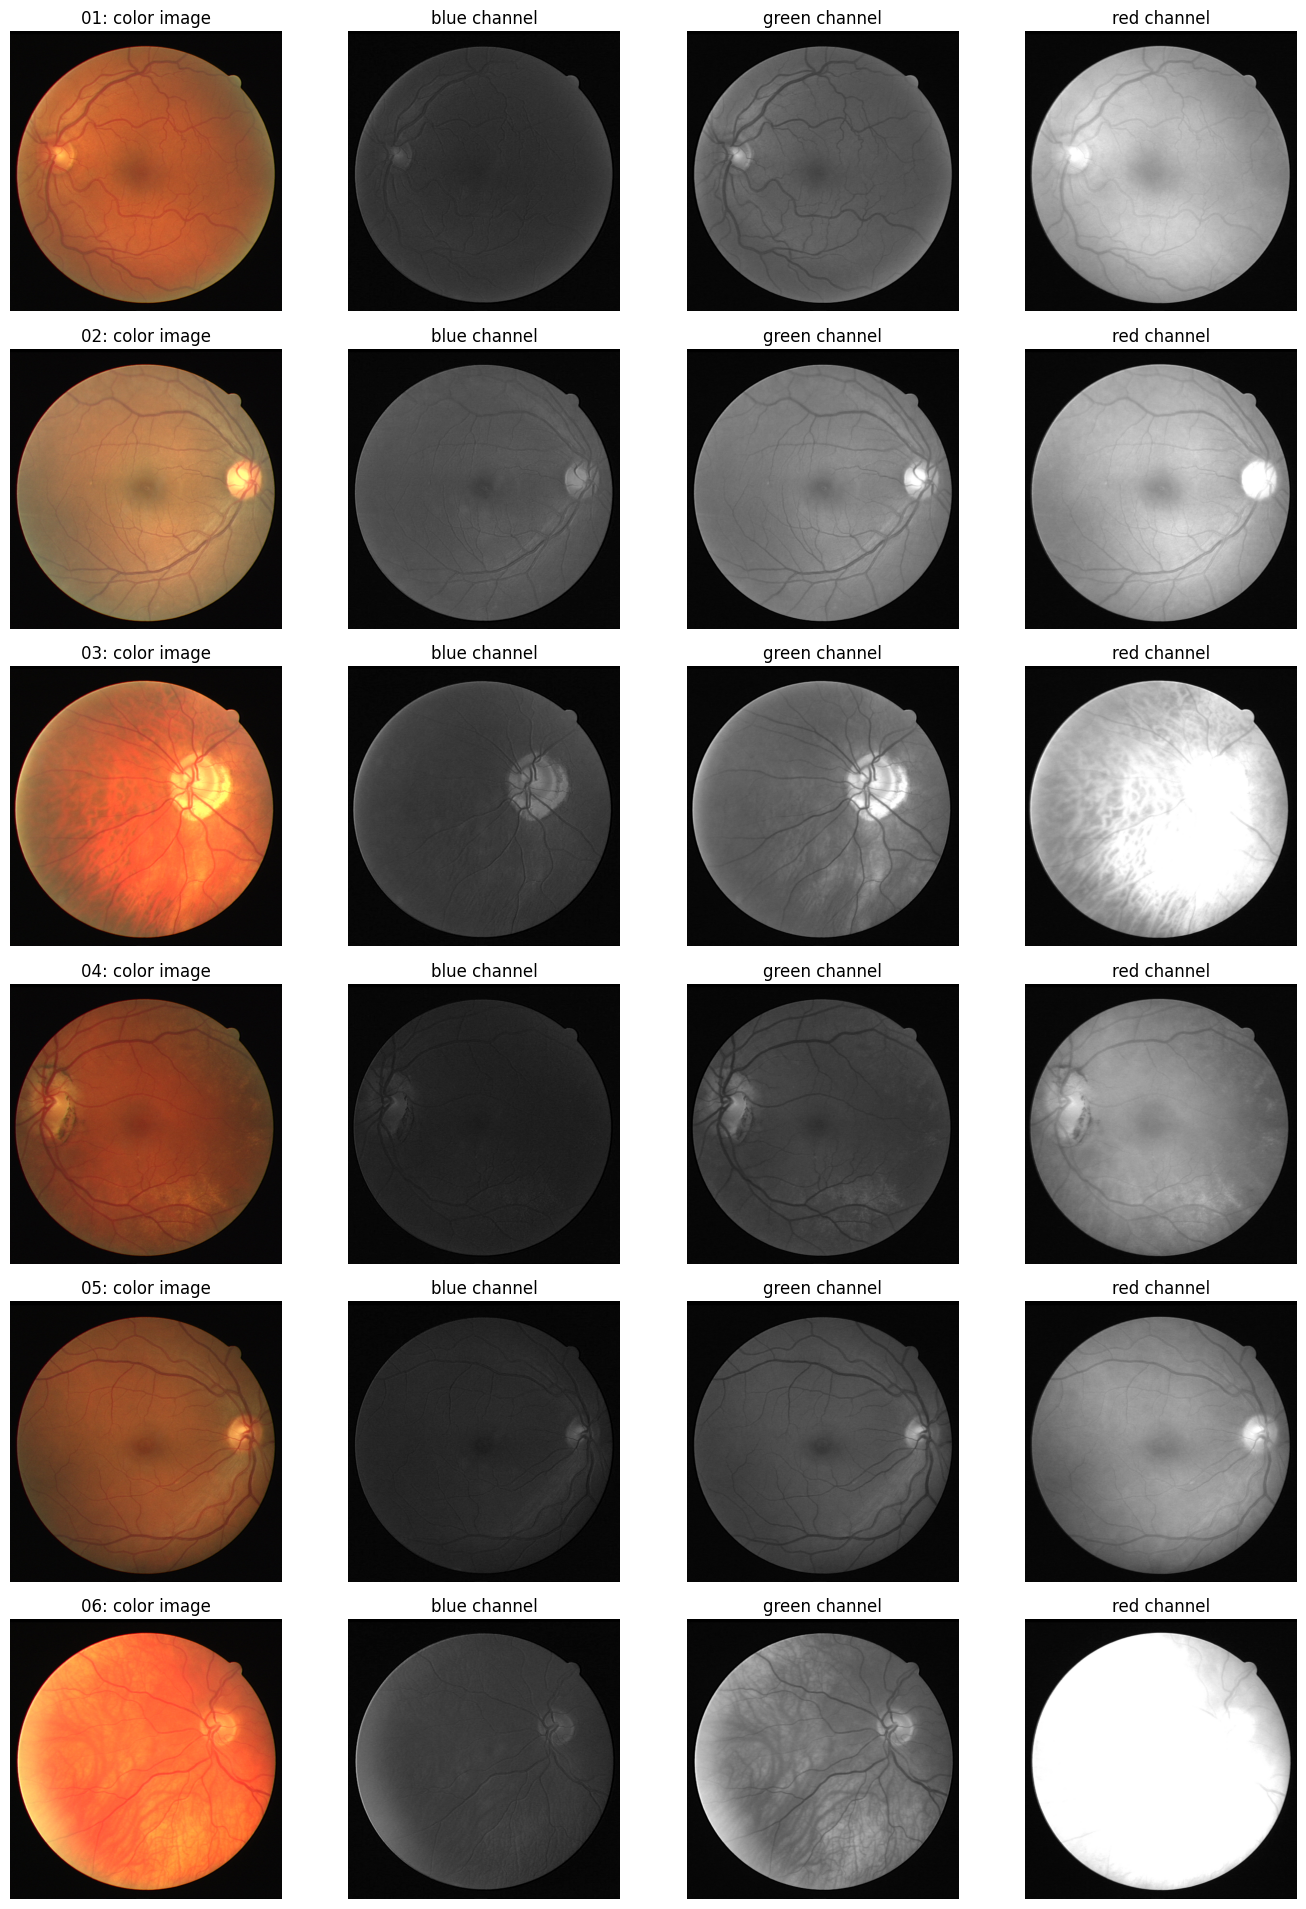

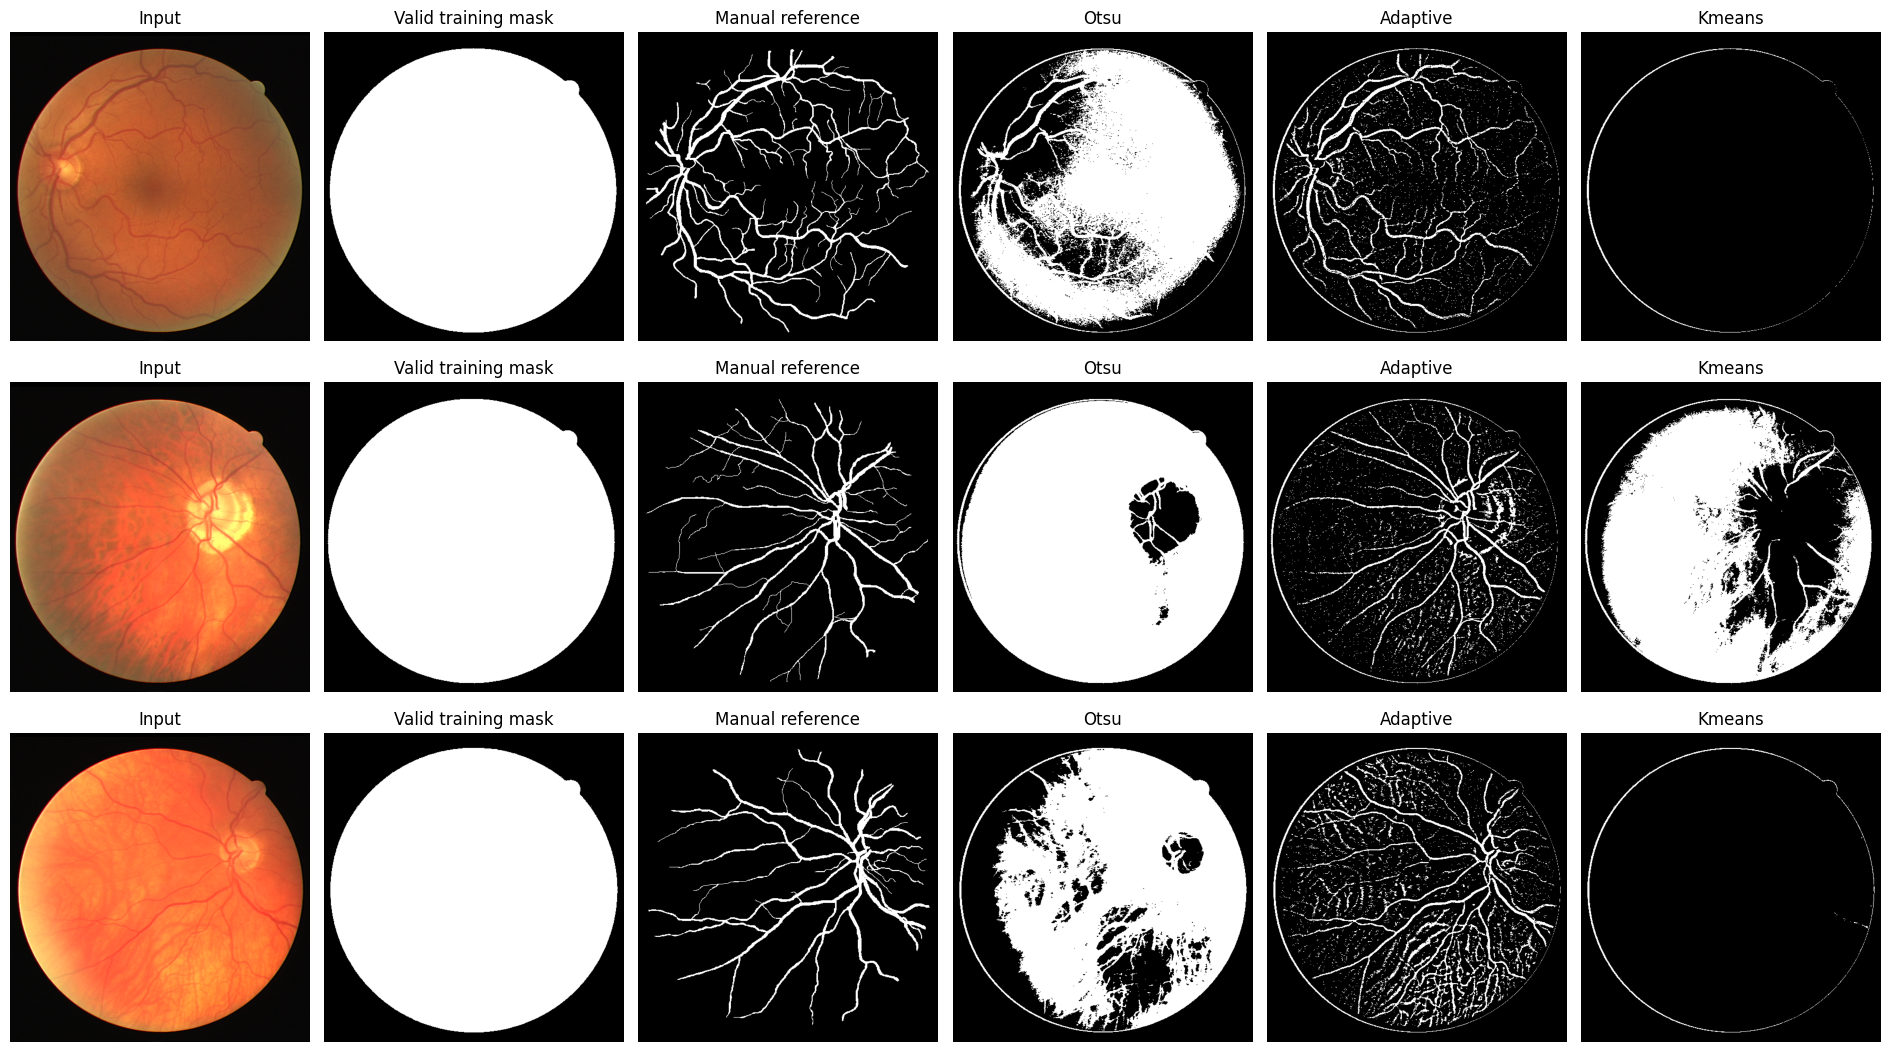

Top adaptive sweep on these references: block_size=35, C=5, mean Dice=0.6157.
Top K-means sweep on these references: K=2, mean Dice=0.1967.
Saved CSV tables and figures to c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\5 Region Extraction\outputs in 20.9 seconds.


In [3]:
import time

BASE_CONFIGS = {
    "otsu": {},
    "adaptive": {"block_size": 25, "C": 5},
    "kmeans": {"k": 3, "random_seed": 0},
}
METRIC_NAMES = ("Dice", "Precision", "Recall")


def evaluate_case(image_id, method, channel="green", preprocessing="raw", config=None):
    item = DATASET[image_id]
    prepared = PREPARED[(image_id, channel, preprocessing)]
    options = dict(config or {})
    options["valid_mask"] = item["valid_mask"]
    prediction = extract_vessels(prepared, method, options)
    metrics = binary_metrics(prediction, item["reference"], item["valid_mask"])
    return prediction, metrics


def write_csv(filename, rows):
    if not rows:
        raise ValueError(f"No rows to write for {filename}.")
    fieldnames = list(dict.fromkeys(key for row in rows for key in row))
    with (OUTPUT_DIR / filename).open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


def mean_by(records, group_fields):
    groups = {}
    for record in records:
        key = tuple(record.get(field) for field in group_fields)
        groups.setdefault(key, []).append(record)
    summaries = []
    for key, group in groups.items():
        summary = dict(zip(group_fields, key))
        for metric in METRIC_NAMES:
            summary[metric] = float(np.mean([row[metric] for row in group]))
        summaries.append(summary)
    return summaries


def show_table(title, rows, limit=30):
    if not rows:
        print(f"{title}: no rows")
        return
    columns = list(rows[0])
    header = "".join(f"<th>{html.escape(str(column))}</th>" for column in columns)
    body = []
    for row in rows[:limit]:
        cells = []
        for column in columns:
            value = row.get(column)
            if isinstance(value, (float, np.floating)):
                value = f"{value:.4f}"
            elif value is None:
                value = ""
            cells.append(f"<td>{html.escape(str(value))}</td>")
        body.append("<tr>" + "".join(cells) + "</tr>")
    suffix = f"<p>Showing {limit} of {len(rows)} rows.</p>" if len(rows) > limit else ""
    display(HTML(f"<h4>{html.escape(title)}</h4><table><thead><tr>{header}</tr></thead><tbody>{''.join(body)}</tbody></table>{suffix}"))


def dataset_characteristics():
    rows = []
    for image_id, item in DATASET.items():
        image = item["image"]
        valid = item["valid_mask"]
        reference = item["reference"] & valid
        row = {
            "image_id": image_id,
            "height": image.shape[0],
            "width": image.shape[1],
            "valid_fov_fraction": float(valid.mean()),
            "reference_vessel_fraction": float(reference.sum() / valid.sum()),
            "median_reference_vessel_width_px": estimate_median_vessel_width(reference),
        }
        for name, index in CHANNEL_INDEX.items():
            values = image[:, :, index][valid]
            row[f"{name}_mean"] = float(values.mean())
            row[f"{name}_std"] = float(values.std())
            row[f"{name}_p95_minus_p5"] = float(np.percentile(values, 95) - np.percentile(values, 5))
        rows.append(row)
    return rows


def metric_row(image_id, method, metrics, channel="green", preprocessing="raw", **parameters):
    row = {
        "image_id": image_id,
        "method": method,
        "channel": channel,
        "preprocessing": preprocessing,
    }
    row.update(parameters)
    row.update(metrics)
    return row


start_time = time.perf_counter()
characteristics = dataset_characteristics()
write_csv("dataset_characteristics.csv", characteristics)
show_table("Image and reference characteristics", characteristics)

# Main method comparison: same green-channel input and no contrast enhancement.
main_records = []
main_predictions = {}
for image_id in DATASET:
    for method in METHODS:
        prediction, metrics = evaluate_case(image_id, method, config=BASE_CONFIGS[method])
        main_predictions[(image_id, method)] = prediction
        main_records.append(metric_row(image_id, method, metrics, **BASE_CONFIGS[method]))
main_means = mean_by(main_records, ["method"])
write_csv("metrics_per_image.csv", main_records)
write_csv("metrics_mean.csv", main_means)
show_table("Main comparison - per-image metrics", main_records)
show_table("Main comparison - mean across images", main_means)

# Compare all three BGR color channels for every extraction method.
channel_records = []
for image_id in DATASET:
    for channel in ("green", "red", "blue"):
        for method in METHODS:
            _, metrics = evaluate_case(
                image_id, method, channel=channel, config=BASE_CONFIGS[method]
            )
            channel_records.append(
                metric_row(image_id, method, metrics, channel=channel, **BASE_CONFIGS[method])
            )
channel_means = mean_by(channel_records, ["method", "channel"])
write_csv("channel_comparison_per_image.csv", channel_records)
write_csv("channel_comparison_mean.csv", channel_means)
show_table("Mean metrics by method and color channel", channel_means)

# Isolate adaptive-threshold parameters and K-means cluster count on green, unenhanced images.
parameter_records = []
for image_id in DATASET:
    for block_size in (15, 25, 35):
        for constant in (2, 5, 8):
            _, metrics = evaluate_case(
                image_id,
                "adaptive",
                config={"block_size": block_size, "C": constant},
            )
            parameter_records.append(
                metric_row(image_id, "adaptive", metrics, block_size=block_size, C=constant)
            )
    for k in (2, 3, 4):
        _, metrics = evaluate_case(
            image_id, "kmeans", config={"k": k, "random_seed": 0}
        )
        parameter_records.append(metric_row(image_id, "kmeans", metrics, k=k))
parameter_means = mean_by(parameter_records, ["method", "block_size", "C", "k"])
write_csv("parameter_sweep_per_image.csv", parameter_records)
write_csv("parameter_sweep_mean.csv", parameter_means)
show_table("Mean metrics by adaptive and K-means parameters", parameter_means)

# Compare raw green against green enhanced with CLAHE using the same baseline settings.
preprocessing_records = []
for image_id in DATASET:
    for method in METHODS:
        for preprocessing in ("raw", "clahe"):
            _, metrics = evaluate_case(
                image_id,
                method,
                preprocessing=preprocessing,
                config=BASE_CONFIGS[method],
            )
            preprocessing_records.append(
                metric_row(
                    image_id, method, metrics,
                    preprocessing=preprocessing,
                    **BASE_CONFIGS[method],
                )
            )
preprocessing_means = mean_by(preprocessing_records, ["method", "preprocessing"])
write_csv("preprocessing_comparison_per_image.csv", preprocessing_records)
write_csv("preprocessing_comparison_mean.csv", preprocessing_means)
show_table("Mean metrics: raw green vs. CLAHE green", preprocessing_means)

# Inspect all original images and color channels.
image_ids = list(DATASET)
fig, axes = plt.subplots(len(image_ids), 4, figsize=(14, 3.2 * len(image_ids)))
for row_index, image_id in enumerate(image_ids):
    image = DATASET[image_id]["image"]
    axes[row_index, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[row_index, 0].set_title(f"{image_id}: color image")
    for column, channel in enumerate(("blue", "green", "red"), start=1):
        axes[row_index, column].imshow(PREPARED[(image_id, channel, "raw")], cmap="gray", vmin=0, vmax=255)
        axes[row_index, column].set_title(f"{channel} channel")
    for axis in axes[row_index]:
        axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "retinal_channel_inspection.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

# Show reference and the three main predictions for representative images.
case_ids = [image_id for image_id in ("01", "03", "06") if image_id in DATASET]
fig, axes = plt.subplots(len(case_ids), 6, figsize=(19, 3.6 * len(case_ids)))
if len(case_ids) == 1:
    axes = axes[np.newaxis, :]
for row_index, image_id in enumerate(case_ids):
    item = DATASET[image_id]
    views = [
        (cv2.cvtColor(item["image"], cv2.COLOR_BGR2RGB), "Input", None),
        (item["valid_mask"], "Valid training mask", "gray"),
        (item["reference"] & item["valid_mask"], "Manual reference", "gray"),
    ]
    for method in METHODS:
        views.append((main_predictions[(image_id, method)], method.title(), "gray"))
    for column, (picture, title, cmap) in enumerate(views):
        if cmap:
            axes[row_index, column].imshow(picture, cmap=cmap, vmin=0, vmax=1)
        else:
            axes[row_index, column].imshow(picture)
        axes[row_index, column].set_title(title)
        axes[row_index, column].axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "vessel_extraction_examples.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

best_adaptive = max(
    (row for row in parameter_means if row["method"] == "adaptive"),
    key=lambda row: row["Dice"],
)
best_kmeans = max(
    (row for row in parameter_means if row["method"] == "kmeans"),
    key=lambda row: row["Dice"],
)
print(f"Top adaptive sweep on these references: block_size={best_adaptive['block_size']}, C={best_adaptive['C']}, mean Dice={best_adaptive['Dice']:.4f}.")
print(f"Top K-means sweep on these references: K={best_kmeans['k']}, mean Dice={best_kmeans['Dice']:.4f}.")
print(f"Saved CSV tables and figures to {OUTPUT_DIR} in {time.perf_counter() - start_time:.1f} seconds.")
